# Ödev - İstanbul Kira Fiyatı Tahmini: Makine Öğrenmesi ve Keras ile Derin Öğrenme

## A. Proje Açıklaması

**Amaç ve problem (regresyon):** Web sitelerinden (zingat, hepsiemlak, emlakjet benzeri) toplanan İstanbul kiralık daire ilanlarıyla aylık kira fiyatını tahmin eden bir regresyon modeli kurmak. Önce derslerdeki makine öğrenmesi modelleri (`algo_test`), sonra TensorFlow/Keras ile derin öğrenme (deep learning) regresyonu denenecek ve sonuçlar karşılaştırılacak.

**Veri:** Web kazıma ile toplanıp temizlenen `istanbul_kiralik_temiz_rwz.csv` dosyası (8.306 kiralık ilan, 8 sütun). Hedef değişken **aylık kira fiyatı**.

**Metrik:** R² (belirlilik katsayısı), RMSE (kök ortalama kare hata) ve MAE (ortalama mutlak hata), TL cinsinden.

## B. Kodlar

### Kütüphaneleri yüklüyor ve veriyi okuyoruz

In [1]:
import pandas as pd # tablo işlemleri
import numpy as np # matematik paketi
import matplotlib.pyplot as plt # grafik çizimi
import seaborn as sns # sns havalı grafik oluşturma paketi
import joblib # model kaydetme
from sklearn.model_selection import train_test_split # veriyi bölme
from sklearn.preprocessing import StandardScaler # ölçeklendirme

kira=pd.read_csv('istanbul_kiralik_temiz_rwz.csv') # kiralık ilanlar
kira.head() # ilk satırlar

,district,neighborhood,room,living room,area (m2),age,floor,price
0,Şişli,Meşrutiyet Mah.,1,1,70,9,1,34999
1,Şişli,Merkez Mah.,1,1,90,3,2,7000
2,Şişli,Meşrutiyet Mah.,1,1,85,7,2,34999
3,Kağıthane,Sultan Selim Mah.,2,1,75,19,3,22999
4,Çekmeköy,Cumhuriyet Mah.,1,1,60,5,0,12999


**Sonuç:** Veride 8.306 kiralık ilan ve 8 sütun var: ilçe, mahalle, oda sayısı, salon sayısı, alan (m²), bina yaşı, kat ve aylık kira (TL).

In [2]:
kira.describe().round(1) # sayısal sütunların özeti

,room,living room,area (m2),age,floor,price
count,8306.0,8306.0,8306.0,8306.0,8306.0,8306.0
mean,2.3,1.1,121.5,17.7,3.8,48532.9
std,1.1,4.9,78.0,25.2,4.7,64343.3
min,1.0,0.0,20.0,0.0,-3.0,5000.0
25%,2.0,1.0,80.0,5.0,1.0,20000.0
50%,2.0,1.0,100.0,15.0,2.0,28000.0
75%,3.0,1.0,135.0,28.0,4.0,50000.0
max,23.0,363.0,1000.0,1864.0,21.0,850000.0


**Sonuç:** Kiralar 5.000 ile 850.000 TL arasında, ortanca 28.000 TL; ortalama (48.533 TL) ortancanın çok üstünde, yani pahalı ilanlar dağılımı sağa çekiyor. Salon sayısı 363'e, oda 23'e, bina yaşı 1.864'e kadar çıkıyor: bunlar giriş hataları. Kat -3 (bodrum) ile 21 arasında.

Eksik (boş) değerleri kontrol ediyoruz.

In [3]:
kira.isnull().sum() # sütunlardaki boş değer sayısı

district        0
neighborhood    0
room            0
living room     0
area (m2)       0
age             0
floor           0
price           0
dtype: int64

**Sonuç:** Hiçbir sütunda boş değer yok; doldurulması gereken eksik veri bulunmuyor.

### Kalan veri hatalarını kontrol ediyoruz

Oda, salon ve bina yaşı sütunlarındaki mantıksız değerleri ve fiyatı dışında bütün bilgileri aynı olan ilanları sayıyoruz.

In [4]:
pd.Series({'Salon > 4': (kira['living room']>4).sum(), # mantıksız salon
           'Oda > 10': (kira.room>10).sum(), # mantıksız oda
           'Bina yaşı > 100': (kira.age>100).sum(), # mantıksız yaş
           'Fiyat dışında aynı ilan': kira.drop(columns='price').duplicated().sum()}) # aynı ev farklı fiyat

Salon > 4                    7
Oda > 10                     6
Bina yaşı > 100             10
Fiyat dışında aynı ilan    155
dtype: int64

**Sonuç:** 7 ilanda salon sayısı 4'ten fazla, 6 ilanda oda 10'dan fazla, 10 ilanda bina yaşı 100'ün üstünde. Ayrıca 155 ilan, fiyatı dışında başka bir ilanla birebir aynı (aynı evin farklı fiyatla tekrar ilanı); bunlar eğitim ve teste bölünürse model testte gördüğü evi ezberlemiş olur.

In [5]:
once=len(kira) # başlangıç
kira=kira[(kira['living room']<=4) & (kira.room<=10) & (kira.age<=100)] # giriş hataları
kira=kira[kira.drop(columns='price').duplicated()==False].reset_index(drop=True) # aynı evin tekrarları
pd.Series({'Çıkarılan': once-len(kira), 'Kalan': len(kira)}) # sonuç

Çıkarılan     178
Kalan        8128
dtype: int64

**Sonuç:** 178 hatalı veya tekrar eden ilan çıkarıldı, 8.128 ilan kaldı.

### Keşifsel veri analizi

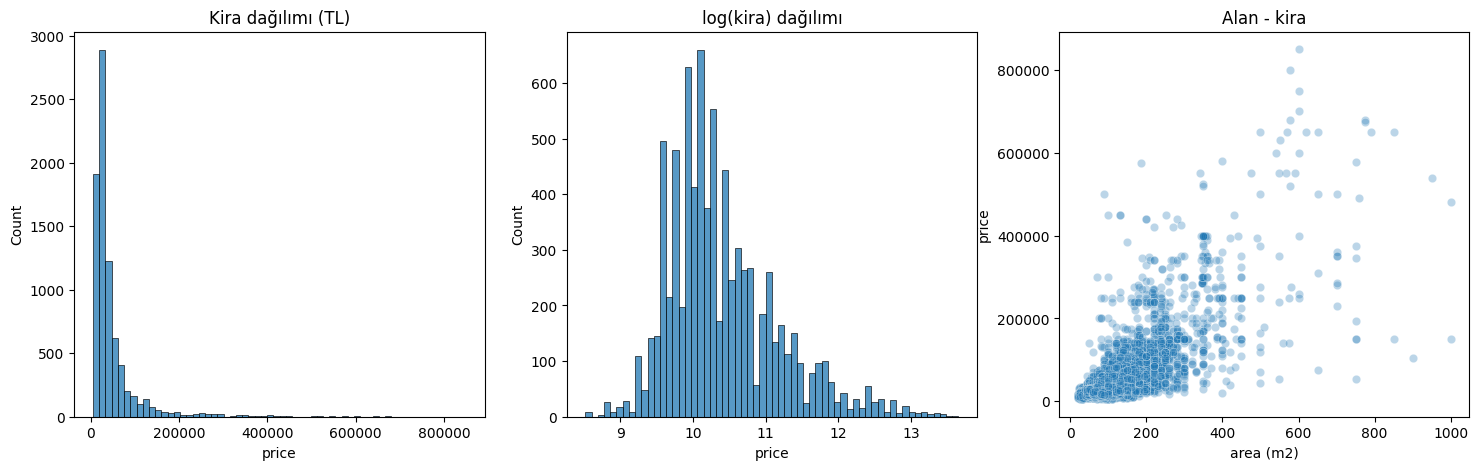

In [6]:
fig,ax=plt.subplots(1,3,figsize=(18,5)) # üç grafik
sns.histplot(kira.price, bins=60, ax=ax[0]).set_title('Kira dağılımı (TL)') # ham kira
sns.histplot(np.log(kira.price), bins=60, ax=ax[1]).set_title('log(kira) dağılımı') # log kira
sns.scatterplot(x=kira['area (m2)'], y=kira.price, alpha=0.3, ax=ax[2]).set_title('Alan - kira') # alan ilişkisi
plt.show() # göster

In [7]:
kira[['room','living room','area (m2)','age','floor','price']].corr().price.drop('price').sort_values().round(3) # kira ile korelasyon

age           -0.135
living room    0.157
floor          0.328
room           0.480
area (m2)      0.733
Name: price, dtype: float64

**Sonuç:** Ham kira dağılımı uzun bir sağ kuyruğa sahip, log(kira) çok daha simetrik; bu yüzden modeller log(kira) öğrenecek. Kira ile en güçlü ilişki alan (0,733), sonra oda sayısı (0,480) ve kat (0,328). Bina yaşı negatif (-0,135): eski binalarda kira biraz daha düşük. Alan-kira grafiğinde aynı alanda kiralar çok farklı; bu farkı konum açıklıyor.

In [8]:
(kira.price/kira['area (m2)']).groupby(kira.district).median().sort_values().round(0).iloc[[0,1,2,-3,-2,-1]] # en ucuz ve en pahalı 3 ilçe (m² kira)

district
Esenyurt      162.0
Esenler       164.0
Sultangazi    171.0
Kadıköy       476.0
Sarıyer       500.0
Beşiktaş      600.0
dtype: float64

**Sonuç:** m² başına ortanca kira en düşük Esenyurt (162 TL), Esenler (164 TL) ve Sultangazi'de (171 TL); en yüksek Kadıköy (476 TL), Sarıyer (500 TL) ve Beşiktaş'ta (600 TL). Aynı şehirde m² kirası ilçeye göre yaklaşık 3,7 kat değişiyor; konum en önemli bilgi.

### Veriyi bölüyor ve konum bilgisini kodluyoruz

Veriyi %80 eğitim, %20 test olarak bölüyoruz. Konum için iki farklı kodlama kullanıyoruz:
- **İlçe:** 38 ilçe olduğu için `pd.get_dummies` ile her ilçeyi ayrı sütun (one-hot encoding) yapıyoruz.
- **Mahalle:** 571 mahalle olduğu için **sadece eğitim ilanlarından** hesaplanan mahallenin ortanca m² kirasını kullanıyoruz (5'ten az ilanı olan mahallede ilçe ortancası). Test ilanlarının kirası girdilere karışmıyor.

Kira sağa çarpık olduğu için modeller log(kira) öğreniyor.

In [9]:
egitim, test = train_test_split(kira, test_size=0.2, random_state=42) # bölme
m2_kira=egitim.price/egitim['area (m2)'] # eğitimde m² kirası
mah=m2_kira.groupby(egitim.neighborhood).agg(['median','count']) # mahalle ortancası (eğitim)
mah=mah[mah['count']>=5]['median'] # en az 5 ilanı olanlar
ilce_m2=m2_kira.groupby(egitim.district).median() # ilçe ortancası (eğitim)
ilceler=sorted(kira.district.unique()) # bütün ilçeler

def hazirla(d): # model girdileri
    x=d[['room','living room','area (m2)','age','floor']].copy() # sayısal sütunlar
    x['mahalle_m2']=d.neighborhood.map(mah).fillna(d.district.map(ilce_m2)).fillna(m2_kira.median()).values # mahalle -> ilçe -> İstanbul
    ilce=pd.get_dummies(pd.Categorical(d.district, categories=ilceler), prefix='ilce', dtype=int) # ilçe sütunları
    ilce.index=x.index # aynı satırlar
    return pd.concat([x, ilce], axis=1) # tablo

x_train=hazirla(egitim) # eğitim girdileri
x_test=hazirla(test) # test girdileri
y_train=np.log(egitim.price) # log kira
y_test=np.log(test.price) # log kira
pd.Series({'x_train': x_train.shape, 'x_test': x_test.shape, 'kodlanan mahalle': len(mah)}) # boyutlar

x_train             (6502, 44)
x_test              (1626, 44)
kodlanan mahalle           330
dtype: object

**Sonuç:** Eğitimde 6.502, testte 1.626 ilan var. Girdi tablosunda 44 sütun bulunuyor: 5 sayısal sütun, mahalle m² kirası ve 38 ilçe sütunu. 330 mahallenin ortanca m² kirası eğitim ilanlarından hesaplandı; diğer mahallelere ilçe ortancası verildi.

### Makine öğrenmesi modellerini karşılaştırıyoruz

Derslerdeki `algo_test` fonksiyonuyla 10 regresyon modelini deniyoruz. Modeller log(kira) öğreniyor; R² log ölçeğinde, RMSE ve MAE TL'ye çevrilerek hesaplanıyor.

In [10]:
from sklearn.linear_model import LinearRegression # doğrusal regresyon
from sklearn.linear_model import Ridge,Lasso # düzenlemeli doğrusal modeller
from sklearn.linear_model import ElasticNet # Ridge ve Lasso karışımı
from sklearn.neighbors import KNeighborsRegressor # en yakın komşu
from sklearn.ensemble import GradientBoostingRegressor # gradient boosting
from sklearn.ensemble import RandomForestRegressor # rastgele orman
from sklearn.tree import ExtraTreeRegressor # tek rastgele ağaç
from sklearn.tree import DecisionTreeRegressor # karar ağacı
from xgboost import XGBRegressor # xgboost
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error # regresyon metrikleri


def algo_test(x_train,x_test,y_train,y_test): # 10 modeli deneyen fonksiyon
        #Bütün modelleri tanımlıyorum
        L=LinearRegression() # doğrusal regresyon
        R=Ridge() # Ridge
        Lass=Lasso() # Lasso
        E=ElasticNet() # ElasticNet
        ETR=ExtraTreeRegressor(random_state=42) # tek rastgele ağaç
        GBR=GradientBoostingRegressor(random_state=42) # gradient boosting
        kn=KNeighborsRegressor() # en yakın komşu
        dt=DecisionTreeRegressor(random_state=42) # karar ağacı
        xgb=XGBRegressor(random_state=42) # xgboost
        rfr=RandomForestRegressor(random_state=42) # rastgele orman

        algos=[L,R,Lass,E,ETR,GBR,kn,dt,xgb,rfr] # model listesi
        algo_names=['Linear','Ridge','Lasso','ElasticNet','Extra Tree','Gradient Boosting','KNeighborsRegressor','Decision Tree','XGBRegressor','Random Forest'] # model isimleri

        r_squared= [] # R² sonuçları
        rmse= [] # RMSE sonuçları
        mae= [] # MAE sonuçları

        #Hata ve doğruluk oranlarını bir tablo haline getirmek için bir dataframe oluşturuyorum
        result=pd.DataFrame(columns=['R_Squared','RMSE','MAE'],index=algo_names) # sonuç tablosu

        print('Modeller eğitiliyor...') # bilgi mesajı
        for algo in algos: # her model için
            p=algo.fit(x_train,y_train).predict(x_test) # eğit ve test verisiyle tahmin et (log fiyat)
            r_squared.append(r2_score(y_test,p)) # R² ekle
            rmse.append(np.sqrt(mean_squared_error(np.exp(y_test),np.exp(p)))) # RMSE ekle (TL)
            mae.append(mean_absolute_error(np.exp(y_test),np.exp(p))) # MAE ekle (TL)
        print('Bütün modeller tamamlandı.') # bilgi mesajı

        #result adlı tabloya doğruluk ve hata oranlarımı yerleştiriyorum
        result.R_Squared=r_squared # R² sütunu
        result.RMSE=rmse # RMSE sütunu
        result.MAE=mae # MAE sütunu

        #oluşturduğum result tablosunu R²'ye göre büyükten küçüğe sıralayıp dönüyor
        rtable=result.sort_values('R_Squared',ascending=False) # R²'ye göre sırala
        return rtable # tabloyu döndür

In [11]:
sonuc=algo_test(x_train,x_test,y_train,y_test) # 10 model
sonuc.round(3) # sonuç tablosu

Modeller eğitiliyor...


Bütün modeller tamamlandı.


,R_Squared,RMSE,MAE
XGBRegressor,0.813,31754.331,11952.671
Random Forest,0.798,30593.722,12270.477
Gradient Boosting,0.784,31851.833,13011.097
Linear,0.747,47938.723,16424.870
Ridge,0.746,47975.768,16438.126
KNeighborsRegressor,0.740,34209.545,14199.379
ElasticNet,0.660,62638.504,20223.310
Decision Tree,0.657,41269.772,16037.913
Lasso,0.654,59342.994,19954.068
Extra Tree,0.636,41942.278,16321.961


**Sonuç:** En iyi model XGBoost (log ölçeğinde R² 0,813, MAE 11.953 TL), ardından Random Forest (0,798) ve Gradient Boosting (0,784). Random Forest'ın RMSE'si (30.594 TL) XGBoost'tan (31.754 TL) biraz daha düşük; yani çok pahalı ilanlardaki büyük hatalarda Random Forest biraz daha iyi. Doğrusal modeller 0,75'te, tek ağaçlı modeller (Decision Tree, Extra Tree) 0,64-0,66'da kaldı.

### En iyi değişkenleri seçiyoruz

En iyi model olan XGBoost'un özellik önemine (feature importance) bakıyoruz. 38 ilçe sütunu tek tek küçük göründüğü için önemlerini **ilçe** adı altında topluyoruz.

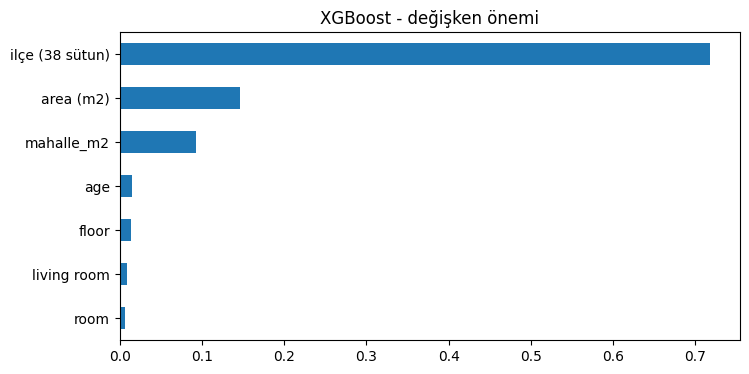

In [12]:
xgb=XGBRegressor(random_state=42).fit(x_train,y_train) # en iyi model (algo_test'teki ayarlarla)
onem=pd.Series(xgb.feature_importances_, index=x_train.columns) # her sütunun önemi
onem=onem.groupby(np.where(onem.index.str.startswith('ilce_'), 'ilçe (38 sütun)', onem.index)).sum().sort_values() # ilçe sütunlarını topla
onem.plot(kind='barh', figsize=(8,4), title='XGBoost - değişken önemi') # grafik
plt.show() # göster

In [13]:
onem.sort_values(ascending=False).round(3) # önem tablosu

ilçe (38 sütun)    0.718
area (m2)          0.146
mahalle_m2         0.093
age                0.015
floor              0.014
living room        0.008
room               0.006
dtype: float32

**Sonuç:** Kirayı en çok **ilçe** belirliyor (38 ilçe sütununun toplam payı 0,718). Sonra **alan** (0,146) ve **mahalle m² kirası** (0,093) geliyor. Bina yaşı (0,015), kat (0,014), salon (0,008) ve oda sayısının (0,006) payı çok küçük. Oda sayısı kira ile 0,480 korelasyonlu olsa da modele alanın ötesinde yeni bilgi katmıyor; çünkü büyük evlerde oda sayısı da fazla.

En önemli değişkenlerle kurulan modelin bütün değişkenlerle kurulan modele göre ne kadar kaybettiğini test ediyoruz: önem payı en düşük iki sayısal değişken çıkarıldığında sonuç değişiyor mu?

In [14]:
az=onem.drop('ilçe (38 sütun)').sort_values().index[:2].tolist() # en az önemli iki değişken
p_az=XGBRegressor(random_state=42).fit(x_train.drop(columns=az),y_train).predict(x_test.drop(columns=az)) # o ikisi olmadan
pd.DataFrame({'R² (log)': [r2_score(y_test,xgb.predict(x_test)), r2_score(y_test,p_az)], # karşılaştırma
              'MAE (TL)': [mean_absolute_error(np.exp(y_test),np.exp(xgb.predict(x_test))), mean_absolute_error(np.exp(y_test),np.exp(p_az))]},
             index=['Bütün değişkenler', 'Çıkarılan: '+', '.join(az)]).round(3) # tablo

,R² (log),MAE (TL)
Bütün değişkenler,0.813,11952.671
"Çıkarılan: room, living room",0.814,11768.185


**Sonuç:** Önemi en düşük iki değişken (oda ve salon sayısı) çıkarıldığında R² 0,813'ten 0,814'e çıktı, MAE 11.953 TL'den 11.768 TL'ye düştü; fark çok küçük. Yani bu iki değişken modele katkı sağlamıyor; kira tahmini için asıl gerekli değişkenler ilçe, alan, mahalle m² kirası, bina yaşı ve kat. Karşılaştırmaların adil olması için sonraki adımlarda bütün değişkenlerle devam ediyoruz.

### Keras ile derin öğrenme regresyonu

Sinir ağı (neural network) girdilerin aynı ölçekte olmasını ister, bu yüzden `StandardScaler` ile ölçeklendiriyoruz (sadece eğitim verisine göre `fit`). Hedef log(kira) de 10 civarında olduğu için eğitim ortalamasını çıkarıp standart sapmaya bölüyoruz; tahminleri sonra geri çeviriyoruz. Bu ölçekleme yapılmadığında ilk denemede ağ kararsız öğrendi ve doğrulama kaybı epoch'lar boyunca yükseldi. Ağ yapısı:
- 3 gizli katman (hidden layer): 128, 64 ve 32 nöron, `relu` aktivasyonu
- Aşırı öğrenmeyi (overfitting) azaltmak için `Dropout(0.2)`
- Çıkış katmanı: 1 nöron, aktivasyon yok (regresyon)
- Kayıp fonksiyonu (loss) `mse`, optimizer `adam`

Eğitim verisinin %20'si doğrulama (validation) için ayrılıyor; doğrulama kaybı 15 epoch boyunca iyileşmezse eğitim duruyor ve en iyi ağırlıklar geri yükleniyor.

In [15]:
import tensorflow as tf # tensorflow
from tensorflow.keras.models import Sequential # sıralı model
from tensorflow.keras.layers import Input, Dense, Dropout # katmanlar
from tensorflow.keras.callbacks import EarlyStopping # erken durdurma

tf.keras.utils.set_random_seed(42) # tekrarlanabilir sonuç (python, numpy, tensorflow)
tf.config.experimental.enable_op_determinism() # her çalıştırmada aynı sonuç
scaler=StandardScaler() # ölçekleyici
xs_train=scaler.fit_transform(x_train) # eğitim: fit + dönüştür
xs_test=scaler.transform(x_test) # test: sadece dönüştür
y_ort, y_std = y_train.mean(), y_train.std() # hedefin eğitim ortalaması ve sapması
ys_train=(y_train-y_ort)/y_std # ölçeklenmiş hedef

ann=Sequential([Input(shape=(xs_train.shape[1],)), # girdi
                Dense(128, activation='relu'), Dropout(0.2), # 1. gizli katman
                Dense(64, activation='relu'), Dropout(0.2), # 2. gizli katman
                Dense(32, activation='relu'), # 3. gizli katman
                Dense(1)]) # çıkış: ölçeklenmiş log kira
ann.compile(optimizer='adam', loss='mse', metrics=['mae']) # derleme
ann.summary() # model özeti

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         5,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,129 (63.00 KB)

 Trainable params: 16,129 (63.00 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
erken=EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True) # erken durdurma
history=ann.fit(xs_train, ys_train, validation_split=0.2, epochs=200, batch_size=32, callbacks=[erken], verbose=2) # eğit, her epoch yazılır
pd.Series({'Eğitilen epoch': len(history.history['loss']), # toplam epoch
           'En iyi epoch': int(np.argmin(history.history['val_loss']))+1, # en iyi epoch
           'En düşük val_loss': min(history.history['val_loss'])}).round(4) # en iyi doğrulama kaybı

Epoch 1/200


E0000 00:00:1793094243.076185     477 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


163/163 - 1s - 7ms/step - loss: 0.4637 - mae: 0.5103 - val_loss: 0.2443 - val_mae: 0.3617


Epoch 2/200


163/163 - 1s - 3ms/step - loss: 0.2994 - mae: 0.4124 - val_loss: 0.2197 - val_mae: 0.3435


Epoch 3/200


... (66 outputs left out)

163/163 - 0s - 2ms/step - loss: 0.1646 - mae: 0.2974 - val_loss: 0.1837 - val_mae: 0.3104


Epoch 37/200


163/163 - 0s - 2ms/step - loss: 0.1602 - mae: 0.2935 - val_loss: 0.1919 - val_mae: 0.3207


Eğitilen epoch       37.0000
En iyi epoch         22.0000
En düşük val_loss     0.1822
dtype: float64

**Sonuç:** Eğitim 37. epoch'ta durdu. Doğrulama kaybı en düşük değerine (0,182) 22. epoch'ta indi; sonraki 15 epoch'ta iyileşmediği için EarlyStopping eğitimi durdurup 22. epoch'un ağırlıklarına döndü.

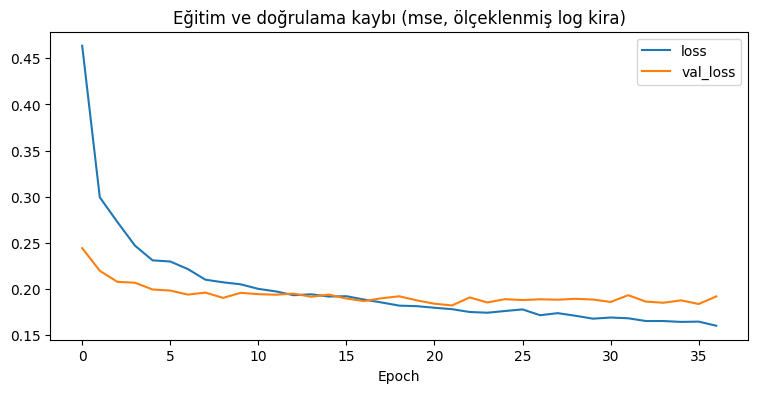

In [17]:
kayip=pd.DataFrame(history.history) # epoch geçmişi
kayip[['loss','val_loss']].plot(figsize=(9,4), title='Eğitim ve doğrulama kaybı (mse, ölçeklenmiş log kira)') # kayıp eğrileri
plt.xlabel('Epoch') # x ekseni
plt.show() # göster

**Sonuç:** Eğitim kaybı 0,46'dan 0,16'ya, doğrulama kaybı 0,24'ten 0,18'e düştü. İlk epoch'larda eğitim kaybının doğrulamadan yüksek olması Dropout'tan kaynaklanıyor (Dropout sadece eğitimde çalışır). Yaklaşık 15. epoch'tan sonra doğrulama kaybı 0,18-0,19'da sabit kalırken eğitim kaybı düşmeye devam ediyor; ezberleme burada başladığı için EarlyStopping devreye girdi.

### Derin öğrenme ile makine öğrenmesini karşılaştırıyoruz

In [18]:
p_ann=ann.predict(xs_test, verbose=0).ravel()*y_std+y_ort # Keras log tahmin (geri ölçeklenmiş)
en_iyi=sonuc.index[0] # algo_test'te en iyi model
karsilastirma=sonuc.loc[[en_iyi]].copy() # en iyi ML sonucu
karsilastirma.loc['Keras (derin öğrenme)']=[r2_score(y_test,p_ann), # R² (log)
                                             np.sqrt(mean_squared_error(np.exp(y_test),np.exp(p_ann))), # RMSE (TL)
                                             mean_absolute_error(np.exp(y_test),np.exp(p_ann))] # MAE (TL)
p_xgb=xgb.predict(x_test) # en iyi ML modeli (XGBoost) log tahmin
karsilastirma['R² (TL)']=[r2_score(np.exp(y_test),np.exp(p_xgb)), r2_score(np.exp(y_test),np.exp(p_ann))] # TL ölçeğinde R²
karsilastirma['Ortanca % hata']=[np.median(np.abs(np.exp(p_xgb)-np.exp(y_test))/np.exp(y_test))*100, np.median(np.abs(np.exp(p_ann)-np.exp(y_test))/np.exp(y_test))*100] # tipik hata
karsilastirma.round(3) # tablo

E0000 00:00:1793094255.199531     477 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,R_Squared,RMSE,MAE,R² (TL),Ortanca % hata
XGBRegressor,0.813,31754.331,11952.671,0.758,16.248
Keras (derin öğrenme),0.794,36114.768,13848.281,0.687,18.479


**Sonuç:** Keras modeli testte log ölçeğinde **R² 0,794**, TL cinsinden R² 0,687, MAE 13.848 TL ve ortanca %18,5 hata verdi. XGBoost her ölçütte daha iyi: R² 0,813 (log) ve 0,758 (TL), MAE 11.953 TL, ortanca hata %16,2. Bu boyutta (8 bin satır, 44 sütun) tablo verisinde ağaç tabanlı modellerin sinir ağını geçmesi beklenen bir durum; Keras log ölçeğinde Random Forest (0,798) ile benzer seviyede.

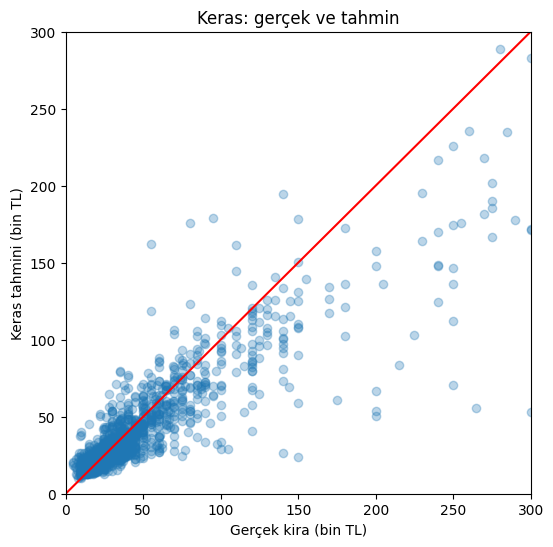

In [19]:
fig,ax=plt.subplots(figsize=(6,6)) # tek grafik
ax.scatter(np.exp(y_test)/1000, np.exp(p_ann)/1000, alpha=0.3) # gerçek - tahmin
ax.plot([0,300],[0,300], color='red') # doğru tahmin çizgisi
ax.set_xlim(0,300); ax.set_ylim(0,300) # 300 bin TL'ye kadar
ax.set_xlabel('Gerçek kira (bin TL)'); ax.set_ylabel('Keras tahmini (bin TL)'); ax.set_title('Keras: gerçek ve tahmin') # etiketler
plt.show() # göster

**Sonuç:** Ucuz ve orta fiyatlı evlerde (50 bin TL'ye kadar) noktalar kırmızı çizginin çevresinde toplanıyor. 100 bin TL'nin üstündeki evlerde dağılım genişliyor ve model birçok pahalı evi olduğundan düşük tahmin ediyor; veride pahalı ilan az olduğu için model bu evleri iyi öğrenemiyor.

### Örnek ev için tahmin

Aynı 2+1, 100 m², 10 yaşında, 3. kattaki evin kirasını iki farklı ilçede iki modelle tahmin ediyoruz.

In [20]:
ornek=pd.DataFrame({'district':['Beşiktaş','Esenyurt'], 'neighborhood':['Levent Mah.','Yenikent Mah.'], # iki konum
                    'room':[2,2], 'living room':[1,1], 'area (m2)':[100,100], 'age':[10,10], 'floor':[3,3]}) # aynı ev
x_ornek=hazirla(ornek) # girdiler
pd.DataFrame({'İlçe': ornek.district, 'Mahalle': ornek.neighborhood, # konum
              'Keras (TL)': np.exp(ann.predict(scaler.transform(x_ornek), verbose=0).ravel()*y_std+y_ort).round(-2), # derin öğrenme
              'XGBoost (TL)': np.exp(xgb.predict(x_ornek)).round(-2)}) # makine öğrenmesi

,İlçe,Mahalle,Keras (TL),XGBoost (TL)
0,Beşiktaş,Levent Mah.,64000.0,105900.0
1,Esenyurt,Yenikent Mah.,14600.0,15600.0


**Sonuç:** Aynı ev için Esenyurt Yenikent'te Keras 14.600 TL, XGBoost 15.600 TL tahmin ediyor (bu mahallede sadece 2 ilan olduğu için ilçe ortancası kullanıldı). Beşiktaş Levent'te ise Keras 64.000 TL, XGBoost 105.900 TL tahmin ediyor; Levent'teki 74 ilanın ortanca kirası 152.500 TL. Pahalı bölgede iki modelin birbirinden bu kadar ayrılması, pahalı evlerdeki belirsizliği gösteriyor.

### Modeli kaydediyoruz

In [21]:
ann.save('istanbul_kira_keras_rwz.keras') # keras modeli
joblib.dump({'scaler':scaler, 'y_ort':y_ort, 'y_std':y_std, 'mahalle_m2':mah, 'ilce_m2':ilce_m2, 'ilceler':ilceler, 'sutunlar':list(x_train.columns)}, 'istanbul_kira_kodlama_rwz.pkl') # ölçekleyici ve kodlamalar

['istanbul_kira_kodlama_rwz.pkl']

## C. Sonuçların Değerlendirilmesi

| Adım | Sonuç |
|---|---|
| Veri | 8.306 → 8.128 ilan (178 hatalı veya tekrar), boş değer yok |
| En önemli değişkenler | İlçe (0,718), alan (0,146), mahalle m² kirası (0,093) |
| En iyi makine öğrenmesi modeli | XGBoost: R² 0,813 (log), 0,758 (TL), MAE 11.953 TL |
| Random Forest / Gradient Boosting | R² 0,798 / 0,784 (log); MAE 12.270 / 13.011 TL |
| Keras (derin öğrenme) | R² 0,794 (log), 0,687 (TL), MAE 13.848 TL; 37 epoch, en iyi 22. epoch |

- **Karşılaştırma:** XGBoost en iyi model; Keras log ölçeğinde Random Forest'a yakın ama TL cinsinde daha zayıf. Modeller tipik bir evde kirayı %16-19 hatayla tahmin ediyor.
- **Değişken seçimi:** Kirayı en çok konum (ilçe ve mahalle) ve alan belirliyor. Oda ve salon sayısı çıkarıldığında sonuç değişmedi (R² 0,814).
- **Güçlü yön:** Ucuz ve orta fiyatlı evlerde tahminler gerçeğe yakın.
- **Zayıf yön:** 100 bin TL üstü evlerde hata büyüyor ve modeller pahalı evleri düşük tahmin ediyor. Veride site, eşya, otopark, manzara gibi pahalı evleri ayıran bilgiler yok.

## D. Kodun Değerlendirilmesi

- Veri, web kazıma ile toplanıp temizlenen İstanbul kira ilanları dosyasından okundu.
- Boş değer kontrolü yapıldı; oda, salon, bina yaşı hataları ve aynı evin tekrar ilanları temizlendi.
- Mahalle kodlaması sadece eğitim ilanlarından hesaplandı, `StandardScaler` sadece eğitim verisine göre `fit` edildi; test verisi hiçbir adımda modele sızmadı.
- Makine öğrenmesi için derslerdeki `algo_test` fonksiyonu değiştirilmeden kullanıldı; Gradient Boosting ve Random Forest bu fonksiyonun içinde.
- Keras modelinde hedef de ölçeklendi; bu yapılmadığında ilk denemede ağ kararsız öğrendi ve test R² değeri çok düşük çıktı.
- `tf.keras.utils.set_random_seed(42)` ve `enable_op_determinism()` ile Keras sonuçları sabitlendi; notebook iki kez çalıştırılıp aynı sonuçlar alındı. Farklı TensorFlow sürümünde veya GPU'da sayılar küçük farklarla değişebilir.
- **Sınırlılıklar:** Pahalı evlerin sayısı az; hiperparametre (katman sayısı, nöron, öğrenme oranı) araması yapılmadı. Kaggle tipi ayrı bir test dosyası olmadığı için tahmin, verinin ayrılmış %20'lik test kısmında ve örnek evlerde yapıldı.

**Kaydedilen dosyalar:** `istanbul_kira_keras_rwz.keras`, `istanbul_kira_kodlama_rwz.pkl`

## E. Genel Sonuç

İstanbul kira ilanlarıyla aylık kira fiyatı hem makine öğrenmesi hem de Keras ile derin öğrenme regresyonu kullanılarak tahmin edildi. En iyi sonucu XGBoost verdi (test R² 0,813 log, 0,758 TL; MAE 11.953 TL). Keras modeli log ölçeğinde buna yakın kaldı (R² 0,794), TL cinsinden daha zayıf (R² 0,687; MAE 13.848 TL). Kirayı en çok ilçe, alan ve mahalle belirliyor. Ucuz ve orta fiyatlı evlerde tahminler iyi, 100 bin TL üstü evlerde hata büyüyor. Pahalı ilan sayısının artırılması ve site, eşya, otopark gibi bilgilerin veriye eklenmesi modeli iyileştirebilir.